<a href="https://colab.research.google.com/github/suryamanoj4/smai-a5/blob/main/SMAI_A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies
!pip install -q kaggle torch torchvision torchmetrics \
    pandas numpy matplotlib seaborn pillow tqdm \
    scikit-learn imagehash python-dotenv

In [ ]:
import os
from getpass import getpass

KAGGLE_USERNAME = input("Enter Kaggle username: ")
KAGGLE_KEY = getpass("Enter Kaggle API key: ")

env_content = f"""
KAGGLE_USERNAME={KAGGLE_USERNAME}
KAGGLE_KEY={KAGGLE_KEY}
"""

with open("/content/.env", "w") as f:
    f.write(env_content)

print(".env file created successfully!")

Enter Kaggle username: suryamanoj4
Enter Kaggle API key: ··········
.env file created successfully!


In [ ]:
from dotenv import load_dotenv
import os
import json

load_dotenv("/content/.env")

KAGGLE_USERNAME = os.getenv("KAGGLE_USERNAME")
KAGGLE_KEY = os.getenv("KAGGLE_KEY")

if not KAGGLE_USERNAME or not KAGGLE_KEY:
    raise ValueError("Kaggle credentials not found!")

os.makedirs("/root/.kaggle", exist_ok=True)

kaggle_config = {
    "username": KAGGLE_USERNAME,
    "key": KAGGLE_KEY
}

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_config, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle authentication configured!")

Kaggle authentication configured!


In [ ]:
import os
import zipfile
from pathlib import Path

DATASET_NAME = "sayehkargari/disney-characters-dataset"
DOWNLOAD_DIR = "/content/dataset"
EXTRACT_DIR = "/content/disney_dataset"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

!kaggle datasets download \
    -d sayehkargari/disney-characters-dataset \
    -p /content/dataset

zip_files = list(Path(DOWNLOAD_DIR).glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("Dataset download failed!")

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset downloaded and extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/sayehkargari/disney-characters-dataset
License(s): unknown
100% 609M/609M [00:09<00:00, 68.7MB/s]

Dataset downloaded and extracted successfully!


In [ ]:
!du -sh /content/disney_dataset
!find /content/disney_dataset -maxdepth 3 -type d

641M	/content/disney_dataset
/content/disney_dataset
/content/disney_dataset/cartoon
/content/disney_dataset/cartoon/test
/content/disney_dataset/cartoon/test/pumba
/content/disney_dataset/cartoon/test/mickey
/content/disney_dataset/cartoon/test/pooh
/content/disney_dataset/cartoon/test/donald
/content/disney_dataset/cartoon/test/minion
/content/disney_dataset/cartoon/test/olaf
/content/disney_dataset/cartoon/train
/content/disney_dataset/cartoon/train/pumba
/content/disney_dataset/cartoon/train/mickey
/content/disney_dataset/cartoon/train/pooh
/content/disney_dataset/cartoon/train/donald
/content/disney_dataset/cartoon/train/minion
/content/disney_dataset/cartoon/train/olaf


In [ ]:
# question 1 CNNs part A

import os
import random
import hashlib
import shutil
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile, UnidentifiedImageError
from tqdm.auto import tqdm

import torch
from torchvision import datasets
from torchvision.datasets.folder import IMG_EXTENSIONS
import imagehash

warnings.filterwarnings("ignore")

SEED = 36
random.seed(SEED)
np.random.seed(SEED)

CLASSES = [
    "donald",
    "mickey",
    "minion",
    "olaf",
    "pooh",
    "pumba"
]
SPLITS = ["train", "test"]

dataset_root = Path("/content/disney_dataset/cartoon")
TEST_DIR = dataset_root/"test"
TRAIN_DIR = dataset_root/"train"

assert TRAIN_DIR.exists(), f"Missing directory: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Missing directory: {TEST_DIR}"

AUDIT_DIR = Path("/content/audit_results")
CLEANED_DIR = Path("/content/disney_cleaned")
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

EMAIL_USERNAME = "manoj.pentakota"

TARGET_SIZE = (64, 64)
BACKGROUND_COLOR = (255, 255, 255)

print("Configuration completed.")
print("Classes:", CLASSES)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)


Configuration completed.
Classes: ['donald', 'mickey', 'minion', 'olaf', 'pooh', 'pumba']
Training directory: /content/disney_dataset/cartoon/train
Testing directory: /content/disney_dataset/cartoon/test


In [ ]:
class DatasetAuditor:
    """
    audits the dataset
    """

    def __init__(self, train_dir, test_dir, classes):
        self.split_dirs = {
            "train": Path(train_dir),
            "test": Path(test_dir)
        }

        self.classes = classes
        self.inventory = None
        self.decode_results = None
        self.image_metadata = None

    def get_files(self, split, class_name):
        class_dir = self.split_dirs[split] / class_name
        if not class_dir.exists():
            return []
        return [
            p for p in class_dir.rglob("*")
            if p.is_file()
        ]

    def get_file_hash(self, file_path):
        sha256 = hashlib.sha256()
        with open(file_path, "rb") as f:
            for chunk in iter(lambda: f.read(8192), b""):
                sha256.update(chunk)
        return sha256.hexdigest()

    def inventory_files(self):
        """
        counts files per split, class and extension.
        slso identifies hidden files and unsupported extensions.
        """
        records = []
        for split in SPLITS:
            for class_name in self.classes:
                files = self.get_files(split, class_name)
                for file_path in files:
                    extension = file_path.suffix.lower()
                    records.append({
                        "split": split,
                        "class": class_name,
                        "filename": file_path.name,
                        "path": str(file_path),
                        "extension": extension if extension else "[no extension]",
                        "is_hidden": file_path.name.startswith("."),
                        "is_supported_by_imagefolder":
                            extension in IMG_EXTENSIONS
                    })
        self.inventory = pd.DataFrame(records)
        return self.inventory

    def get_inventory_summary(self):
        if self.inventory is None:
            self.inventory_files()

        summary = (
            self.inventory
            .groupby(["split", "class"])
            .size()
            .unstack(fill_value=0)
        )
        extension_summary = (
            self.inventory
            .groupby(["split", "extension"])
            .size()
            .unstack(fill_value=0)
        )
        split_summary = (
            self.inventory
            .groupby("split")
            .size()
            .rename("total_files")
        )
        return summary, extension_summary, split_summary

    def compare_imagefolder(self):
        """
        compare our inventory againt torchvision ImageFolder.
        ImageFolder only recognises supported image extensions.
        """
        results = []
        for split, directory in self.split_dirs.items():
            dataset = datasets.ImageFolder(str(directory))
            our_count = len(
                self.inventory[
                    (self.inventory["split"] == split) &
                    (self.inventory["is_supported_by_imagefolder"])
                ]
            )
            results.append({
                "split": split,
                "our_supported_file_count": our_count,
                "imagefolder_count": len(dataset),
                "difference": our_count - len(dataset)
            })
        return pd.DataFrame(results)

    def inspect_image(self, file_path):
        """
        fully decode an image. first attempts strict decoding.
        if that fails, retries with truncated-image support enabled.
        for GIFs, checks all frames.
        """
        result = {
            "path": str(file_path),
            "status": None,
            "width": None,
            "height": None,
            "mode": None,
            "format": None,
            "n_frames": None,
            "is_animated": False,
            "was_truncated": False,
            "error": None
        }
        try:
            ImageFile.LOAD_TRUNCATED_IMAGES = False
            with Image.open(file_path) as img:
                result["format"] = img.format
                result["width"], result["height"] = img.size
                result["mode"] = img.mode
                result["n_frames"] = getattr(img, "n_frames", 1)
                result["is_animated"] = result["n_frames"] > 1
                for frame_index in range(result["n_frames"]):
                    img.seek(frame_index)
                    img.load()
            result["status"] = "valid"
        except Exception as strict_error:
            try:
                ImageFile.LOAD_TRUNCATED_IMAGES = True
                with Image.open(file_path) as img:
                    result["format"] = img.format
                    result["width"], result["height"] = img.size
                    result["mode"] = img.mode
                    result["n_frames"] = getattr(img, "n_frames", 1)
                    result["is_animated"] = result["n_frames"] > 1
                    for frame_index in range(result["n_frames"]):
                        img.seek(frame_index)
                        img.load()

                result["status"] = "truncated_recoverable"
                result["was_truncated"] = True

            except Exception as tolerant_error:
                if isinstance(
                    tolerant_error,
                    (UnidentifiedImageError, IsADirectoryError)
                ):
                    result["status"] = "not_image"
                else:
                    result["status"] = "corrupted"
                result["error"] = str(tolerant_error)
        finally:
            ImageFile.LOAD_TRUNCATED_IMAGES = False
        return result

    def audit_readability(self):
        """
        attempt to decode every file and collect the image metadata
        """
        if self.inventory is None:
            self.inventory_files()
        results = []
        for _, row in tqdm(
            self.inventory.iterrows(),
            total=len(self.inventory),
            desc="Auditing files"
        ):
            result = self.inspect_image(row["path"])
            result.update({
                "split": row["split"],
                "class": row["class"],
                "filename": row["filename"],
                "extension": row["extension"]
            })
            results.append(result)
        self.decode_results = pd.DataFrame(results)
        self.image_metadata = self.decode_results[
            self.decode_results["status"].isin(
                ["valid", "truncated_recoverable"]
            )
        ].copy()
        return self.decode_results

    def get_readability_summary(self):
        return (
            self.decode_results
            .groupby(["split", "status"])
            .size()
            .unstack(fill_value=0)
        )

    def get_gif_summary(self):
        """report GIF counts and animated GIF counts."""

        gif_data = self.decode_results[
            self.decode_results["extension"] == ".gif"
        ]
        return pd.DataFrame({
            "total_gifs": [
                len(gif_data)
            ],
            "animated_gifs": [
                gif_data["is_animated"].sum()
            ],
            "static_gifs": [
                (~gif_data["is_animated"]).sum()
            ]
        })


In [ ]:
auditor = DatasetAuditor(
    train_dir=TRAIN_DIR,
    test_dir=TEST_DIR,
    classes=CLASSES
)

# generate the file inventory
inventory_df = auditor.inventory_files()

print("Total files found:", len(inventory_df))

# save inventory
inventory_df.to_csv(
    AUDIT_DIR / "file_inventory.csv",
    index=False
)

# generate summaries
class_summary, extension_summary, split_summary = (
    auditor.get_inventory_summary()
)

print("\nFiles per split:")
display(split_summary.to_frame())

print("\nFiles per split and class:")
display(class_summary)

print("\nFiles per extension:")
display(extension_summary)


Total files found: 4667

Files per split:


,total_files
split,
test,512
train,4155



Files per split and class:


class,donald,mickey,minion,olaf,pooh,pumba
split,,,,,,
test,109,104,72,87,79,61
train,642,725,710,617,764,697



Files per extension:


extension,.gif,.jpeg,.jpg,.png,[no extension]
split,,,,,
test,79,21,146,266,0
train,631,366,2022,1135,1


In [ ]:
# files not recognised by torchvision ImageFolder
unsupported_files = inventory_df[
    ~inventory_df["is_supported_by_imagefolder"]
].copy()

# now hiidden files
hidden_files = inventory_df[
    inventory_df["is_hidden"]
].copy()

print("Unsupported files:", len(unsupported_files))
print("Hidden files:", len(hidden_files))
print("\nUnsupported extension distribution:")

if len(unsupported_files) > 0:
    display(
        unsupported_files.groupby("extension")
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

print("\nHidden files:")
display(hidden_files[["split", "class", "filename", "path"]].head(30))

# save reports
unsupported_files.to_csv(
    AUDIT_DIR / "unsupported_files.csv",
    index=False
)

hidden_files.to_csv(
    AUDIT_DIR / "hidden_files.csv",
    index=False
)

Unsupported files: 711
Hidden files: 1

Unsupported extension distribution:


,extension,count
0,.gif,710
1,[no extension],1



Hidden files:


,split,class,filename,path
25,train,donald,.jpg,/content/disney_dataset/cartoon/train/donald/.jpg


In [ ]:
imagefolder_comparison = auditor.compare_imagefolder()

print("our inventoiry vs torchvision ImageFolder")
display(imagefolder_comparison)

our inventoiry vs torchvision ImageFolder


,split,our_supported_file_count,imagefolder_count,difference
0,train,3523,3524,-1
1,test,433,433,0


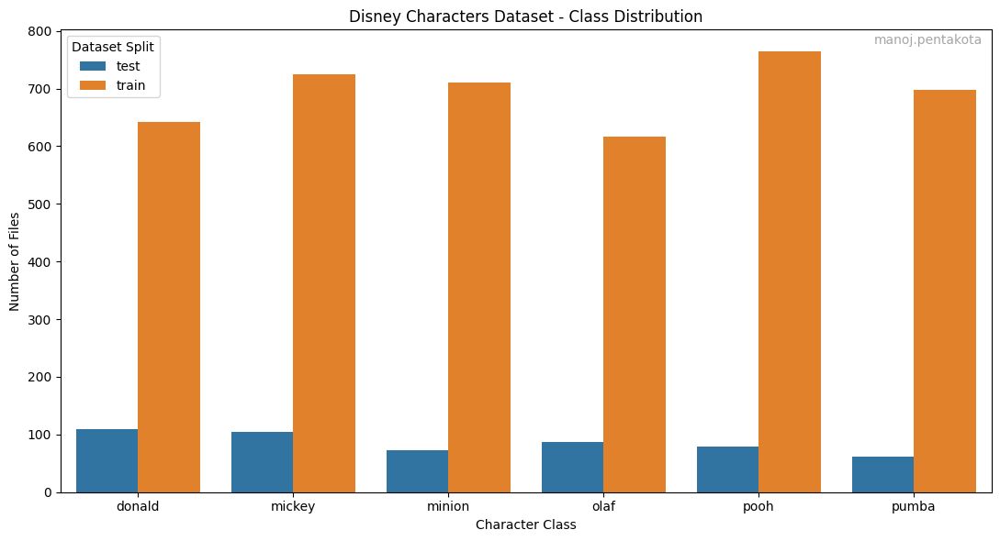

In [ ]:
def plot_class_distribution(inventory):
    """plot the number of files per class in each split"""

    counts = (
        inventory
        .groupby(["class", "split"])
        .size()
        .reset_index(name="count")
    )
    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=counts,
        x="class",
        y="count",
        hue="split"
    )
    plt.title("Disney Characters Dataset - Class Distribution")
    plt.xlabel("Character Class")
    plt.ylabel("Number of Files")
    plt.legend(title="Dataset Split")
    plt.text(
        0.99, 0.99, EMAIL_USERNAME,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig(
        AUDIT_DIR / "class_distribution.png",
        dpi=300
    )
    plt.show()

plot_class_distribution(inventory_df)

In [ ]:
decode_df = auditor.audit_readability()

decode_df.to_csv(
    AUDIT_DIR / "readability_report.csv",
    index=False
)
print("Readability audit completed!")
print("\nReadability summary:")
display(auditor.get_readability_summary())
print("\nFiles requiring attention:")
problematic_files = decode_df[
    decode_df["status"] != "valid"
]
display(
    problematic_files[
        [
            "split",
            "class",
            "filename",
            "status",
            "error"
        ]
    ].head(50)
)

Auditing files:   0%|          | 0/4667 [00:00<?, ?it/s]

Readability audit completed!

Readability summary:


status,truncated_recoverable,valid
split,,
test,0,512
train,1,4154



Files requiring attention:


,split,class,filename,status,error
486,train,donald,history-donald-duck-personality.jpg,truncated_recoverable,None


In [ ]:
gif_summary = auditor.get_gif_summary()

print("GIF Analysis:")
display(gif_summary)
gif_details = decode_df[
    decode_df["extension"] == ".gif"
][
    [
        "split",
        "class",
        "filename",
        "n_frames",
        "is_animated",
        "status"
    ]
]

display(gif_details.head(20))
gif_details.to_csv(
    AUDIT_DIR / "gif_analysis.csv",
    index=False
)

GIF Analysis:


,total_gifs,animated_gifs,static_gifs
0,710,7,703


,split,class,filename,n_frames,is_animated,status
1,train,donald,donaldtuxs.gif,1,False,valid
6,train,donald,donthink.gif,1,False,valid
12,train,donald,donald-duck-policemans.gif,1,False,valid
20,train,donald,nv27s.gif,1,False,valid
21,train,donald,fev17s.gif,1,False,valid
26,train,donald,september169s.gif,1,False,valid
27,train,donald,donald-faces.gif,1,False,valid
34,train,donald,donald_baths.gif,1,False,valid
38,train,donald,nv29s.gif,1,False,valid
40,train,donald,donaldinjureds.gif,1,False,valid


In [ ]:
mode_summary = (
    auditor.image_metadata
    .groupby(["split", "mode"])
    .size()
    .unstack(fill_value=0)
)

print("image colour mode distribution:")
display(mode_summary)

image colour mode distribution:


mode,CMYK,L,LA,P,RGB,RGBA
split,,,,,,
test,0,0,0,99,297,116
train,2,1,1,993,2636,522


In [ ]:
dimension_df = auditor.image_metadata.copy()
dimension_df["aspect_ratio"] = (
    dimension_df["width"] / dimension_df["height"]
)
dimension_df["pixel_count"] = (
    dimension_df["width"] * dimension_df["height"]
)
print("Image dimension statistics:")
display(
    dimension_df[
        ["width", "height", "aspect_ratio", "pixel_count"]
    ].describe()
)
print("\nDimensions by split:")
display(
    dimension_df.groupby("split")[
        ["width", "height", "aspect_ratio"]
    ].describe()
)
dimension_df.to_csv(
    AUDIT_DIR / "image_dimensions.csv",
    index=False
)

Image dimension statistics:


,width,height,aspect_ratio,pixel_count
count,4667.000000,4667.000000,4667.000000,4.667000e+03
mean,602.107564,585.479323,1.069518,6.391607e+05
std,599.838580,558.392690,0.369868,2.162708e+06
min,1.000000,1.000000,0.196246,1.000000e+00
25%,205.000000,214.000000,0.813819,5.037000e+04
50%,490.000000,496.000000,1.000000,2.508800e+05
75%,840.000000,800.000000,1.250000,6.690000e+05
max,9000.000000,8000.000000,3.636364,5.831200e+07



Dimensions by split:


width                                                            \
        count        mean        std   min    25%    50%    75%     max   
split                                                                     
test    512.0  598.916016  384.05831  64.0  236.0  685.0  860.0  2560.0   
train  4155.0  602.500842  621.29548   1.0  201.0  478.0  840.0  9000.0   

       height              ...                 aspect_ratio            \
        count        mean  ...     75%     max        count      mean   
split                      ...                                          
test    512.0  605.679688  ...  823.75  3472.0        512.0  1.052796   
train  4155.0  582.990132  ...  800.00  8000.0       4155.0  1.071578   

                                                              
            std       min       25%  50%       75%       max  
split                                                         
test   0.340442  0.373563  0.800000  1.0  1.266326  2.277778  
train  0.373320  0.196246  0.815261  1.0  1.250000  3.636364  

[2 rows x 24 columns]

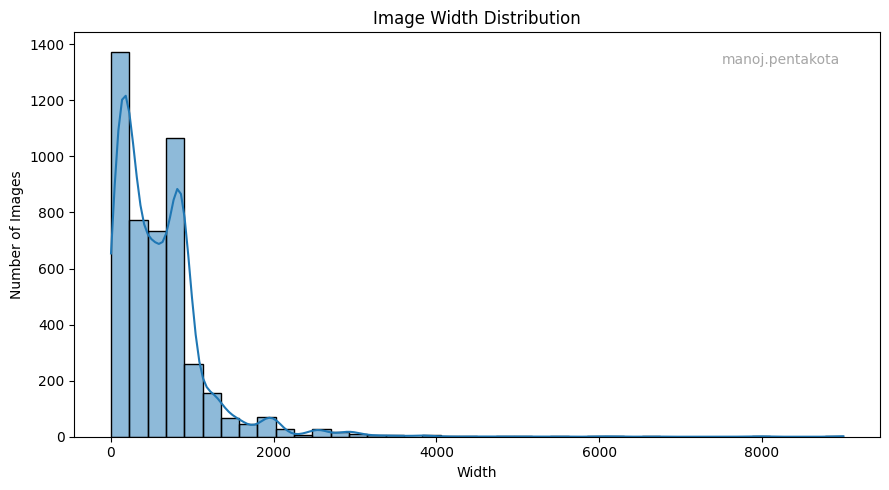

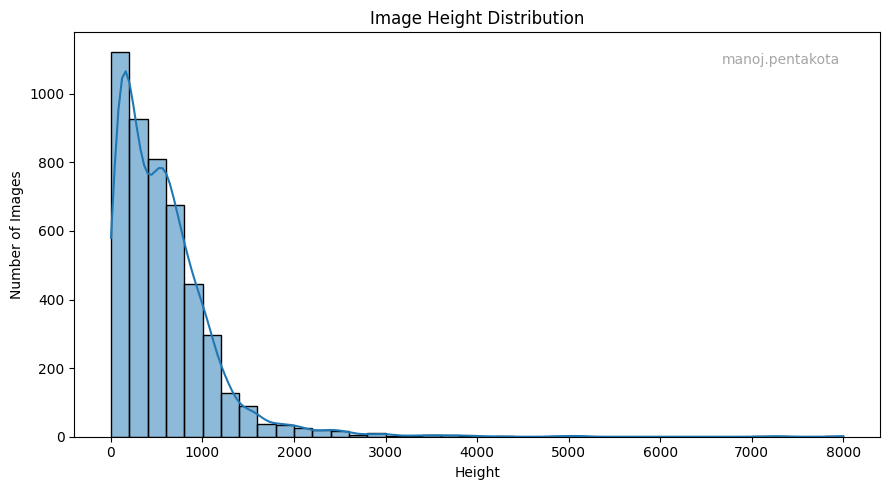

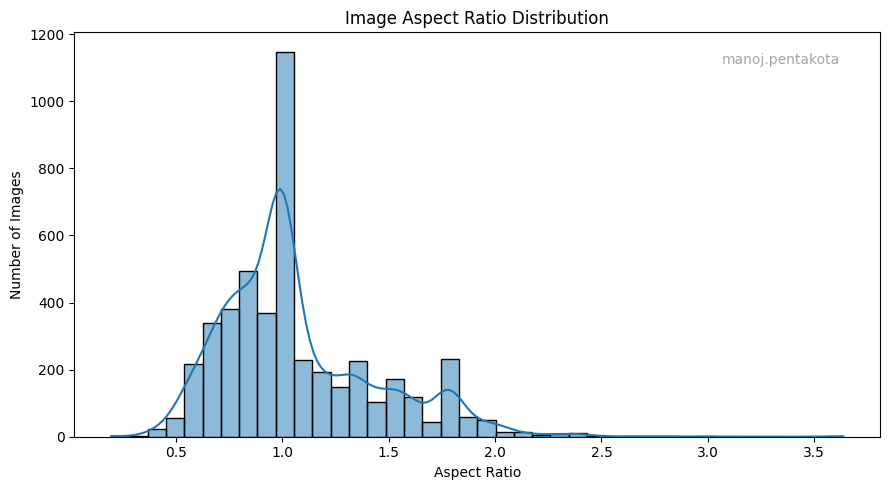

In [ ]:
def plot_dimension_distributions(data):
    """plot width, height and aspect ratio distributions"""

    columns = [
        ("width", "Image Width Distribution"),
        ("height", "Image Height Distribution"),
        ("aspect_ratio", "Image Aspect Ratio Distribution")
    ]
    for column, title in columns:
        plt.figure(figsize=(9, 5))
        sns.histplot(
            data=data,
            x=column,
            bins=40,
            kde=True
        )
        plt.title(title)
        plt.xlabel(column.replace("_", " ").title())
        plt.ylabel("Number of Images")
        plt.text(
            0.95, 0.95, EMAIL_USERNAME,
            ha="right", va="top",
            transform=plt.gca().transAxes,
            fontsize=10, color="gray", alpha=0.7
        )
        plt.tight_layout()
        plt.savefig(
            AUDIT_DIR / f"{column}_distribution.png",
            dpi=300
        )
        plt.show()

plot_dimension_distributions(dimension_df)

for the image sizes and aspect ratios

im going with 64*64 as the reference CNN also used the same input images and also this reduces the GPU compute required while leaving us with a chance for future ablations with other dimensions if required

also we are going with aspect ratio preserving resizinf with padding so that the characters wont sufer stretching from direct resizing

In [ ]:
def calculate_image_hashes(metadata):
    """
    calcuate hashes for valid images
    """
    records = []
    valid_data = metadata[
        metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        )
    ]
    for _, row in tqdm(
        valid_data.iterrows(),
        total=len(valid_data),
        desc="Calculating hashes"
    ):
        file_path = row["path"]
        try:
            sha256 = auditor.get_file_hash(file_path)
            with Image.open(file_path) as img:
                img.seek(0)
                if img.mode == "RGBA":
                    background = Image.new(
                        "RGBA", img.size, BACKGROUND_COLOR + (255,)
                    )
                    img = Image.alpha_composite(
                        background, img.convert("RGBA")
                    ).convert("RGB")
                else:
                    img = img.convert("RGB")
                phash = imagehash.phash(img)
            records.append({
                "path": file_path,
                "split": row["split"],
                "class": row["class"],
                "filename": row["filename"],
                "sha256": sha256,
                "phash": str(phash),
                "phash_int": int(str(phash), 16)
            })

        except Exception as e:
            print(f"Hashing failed: {file_path} | {e}")
    return pd.DataFrame(records)
hash_df = calculate_image_hashes(decode_df)
hash_df.to_csv(
    AUDIT_DIR / "image_hashes.csv",
    index=False
)
print("Images hashed:", len(hash_df))

Calculating hashes:   0%|          | 0/4667 [00:00<?, ?it/s]

Hashing failed: /content/disney_dataset/cartoon/train/donald/history-donald-duck-personality.jpg | image file is truncated (5 bytes not processed)
Images hashed: 4666


In [ ]:
def find_exact_duplicates(hash_data):
    """find groups of files having identical SHA256 hashes"""
    duplicate_groups = (
        hash_data.groupby("sha256")
        .filter(lambda x: len(x) > 1)
        .sort_values("sha256")
    )
    return duplicate_groups

exact_duplicates = find_exact_duplicates(hash_df)
print("Files involved in exact duplicate groups:",
      len(exact_duplicates))

if len(exact_duplicates) > 0:
    print("\nExact duplicate groups:")
    display(
        exact_duplicates[
            ["sha256", "split", "class", "filename", "path"]
        ]
    )
else:
    print("No exact duplicate groups found.")

exact_duplicates.to_csv(
    AUDIT_DIR / "exact_duplicates.csv",
    index=False
)

Files involved in exact duplicate groups: 277

Exact duplicate groups:


,sha256,split,class,filename,path
395,007421f6e90ea1cad8d43d2b967c9084c06ac0f4d9d663...,train,donald,images (12).png,/content/disney_dataset/cartoon/train/donald/i...
33,007421f6e90ea1cad8d43d2b967c9084c06ac0f4d9d663...,train,donald,image (2).png,/content/disney_dataset/cartoon/train/donald/i...
4135,0224a3c26d7df35ab52b6744a0da1569c5728193afa7d9...,train,pumba,4182ab7323f6d6a57480a39ffdbcc3f3.jpg,/content/disney_dataset/cartoon/train/pumba/41...
3469,0224a3c26d7df35ab52b6744a0da1569c5728193afa7d9...,train,pumba,4182ab7323f6d6a57480a39ffdbcc3f3--timon-and-pu...,/content/disney_dataset/cartoon/train/pumba/41...
786,0255fd292fcd8ddea47c7cc2dd402fbee392f3d8caf4ab...,train,mickey,325-3259091_mickeyicon-mickey-mouse-icon-clipa...,/content/disney_dataset/cartoon/train/mickey/3...
...,...,...,...,...,...
1012,fa32d96be32d1720cf5b38678941407c4f71393f1e5f88...,train,mickey,images11.jpg,/content/disney_dataset/cartoon/train/mickey/i...
2844,fd95acb231064c08d06152ac0d1b44eecae759b236f331...,train,pooh,Winnie-The-Pooh.png,/content/disney_dataset/cartoon/train/pooh/Win...
2926,fd95acb231064c08d06152ac0d1b44eecae759b236f331...,train,pooh,Winnie-the-Pooh-Characters.png,/content/disney_dataset/cartoon/train/pooh/Win...
2537,ffe6ab8f48e32d231dbd35171484d15d011e90f9b4c33e...,train,olaf,images (11).jpeg,/content/disney_dataset/cartoon/train/olaf/ima...


In [ ]:
def find_near_duplicates(hash_data, threshold=6):
    """
    identify cross-split near-duplicate images
    hammming distance less than threshold indicates condidate pair
    """
    train_data = hash_data[
        hash_data["split"] == "train"
    ].reset_index(drop=True)

    test_data = hash_data[
        hash_data["split"] == "test"
    ].reset_index(drop=True)

    candidates = []
    for _, test_row in tqdm(
        test_data.iterrows(),
        total=len(test_data),
        desc="Comparing train-test images"
    ):
        test_hash = int(test_row["phash_int"])
        for _, train_row in train_data.iterrows():
            train_hash = int(train_row["phash_int"])
            distance = (
                test_hash ^ train_hash
            ).bit_count()
            if distance <= threshold:
                candidates.append({
                    "train_path": train_row["path"],
                    "test_path": test_row["path"],
                    "train_class": train_row["class"],
                    "test_class": test_row["class"],
                    "hamming_distance": distance,
                    "same_class": (
                        train_row["class"] == test_row["class"]
                    )
                })

    return pd.DataFrame(candidates)

PHASH_THRESHOLD = 6
near_duplicates = find_near_duplicates(
    hash_df,
    threshold=PHASH_THRESHOLD
)
print("Near-duplicate candidate pairs:",len(near_duplicates))
display(
    near_duplicates.sort_values(
        "hamming_distance"
    ).head(30)
)
near_duplicates.to_csv(
    AUDIT_DIR / "near_duplicate_candidates.csv",
    index=False
)

Comparing train-test images:   0%|          | 0/512 [00:00<?, ?it/s]

Near-duplicate candidate pairs: 310


,train_path,test_path,train_class,test_class,hamming_distance,same_class
309,/content/disney_dataset/cartoon/train/pumba/im...,/content/disney_dataset/cartoon/test/pumba/719...,pumba,pumba,0,True
1,/content/disney_dataset/cartoon/train/donald/5...,/content/disney_dataset/cartoon/test/donald/51...,donald,donald,0,True
2,/content/disney_dataset/cartoon/train/donald/d...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
3,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/8f...,donald,donald,0,True
4,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
22,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/7e...,donald,donald,0,True
23,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
24,/content/disney_dataset/cartoon/train/donald/d...,/content/disney_dataset/cartoon/test/donald/do...,donald,donald,0,True
28,/content/disney_dataset/cartoon/train/donald/i...,/content/disney_dataset/cartoon/test/donald/Do...,donald,donald,0,True
29,/content/disney_dataset/cartoon/train/donald/1...,/content/disney_dataset/cartoon/test/donald/12...,donald,donald,0,True


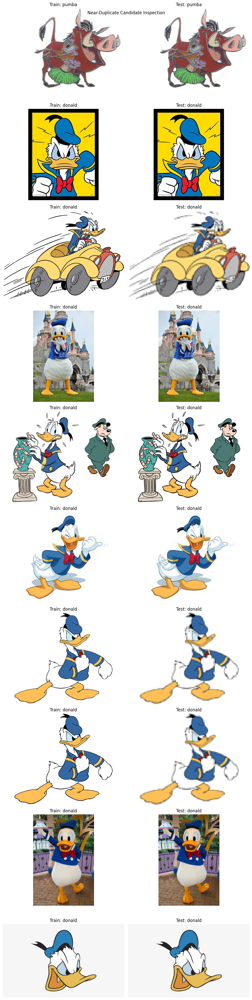

In [ ]:
def display_duplicate_pairs(pairs, num_pairs=10):
    """diplay near duplication pair for manual verificatio"""

    if len(pairs) == 0:
        print("No candidate pairs to display.")
        return
    selected = pairs.sort_values("hamming_distance").head(num_pairs)
    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(10, 4 * len(selected))
    )
    if len(selected) == 1:
        axes = np.array([axes])

    for i, (_, row) in enumerate(selected.iterrows()):
        for j, path in enumerate([
            row["train_path"],
            row["test_path"]
        ]):
            with Image.open(path) as img:
                img.seek(0)
                axes[i, j].imshow(img.convert("RGB"))

            axes[i, j].axis("off")

        axes[i, 0].set_title(
            f"Train: {row['train_class']}"
        )

        axes[i, 1].set_title(
            f"Test: {row['test_class']}"
        )

        axes[i, 0].set_ylabel(
            f"Distance: {row['hamming_distance']}"
        )

    plt.suptitle("Near-Duplicate Candidate Inspection")
    plt.tight_layout()
    plt.show()

display_duplicate_pairs(
    near_duplicates,
    num_pairs=10
)

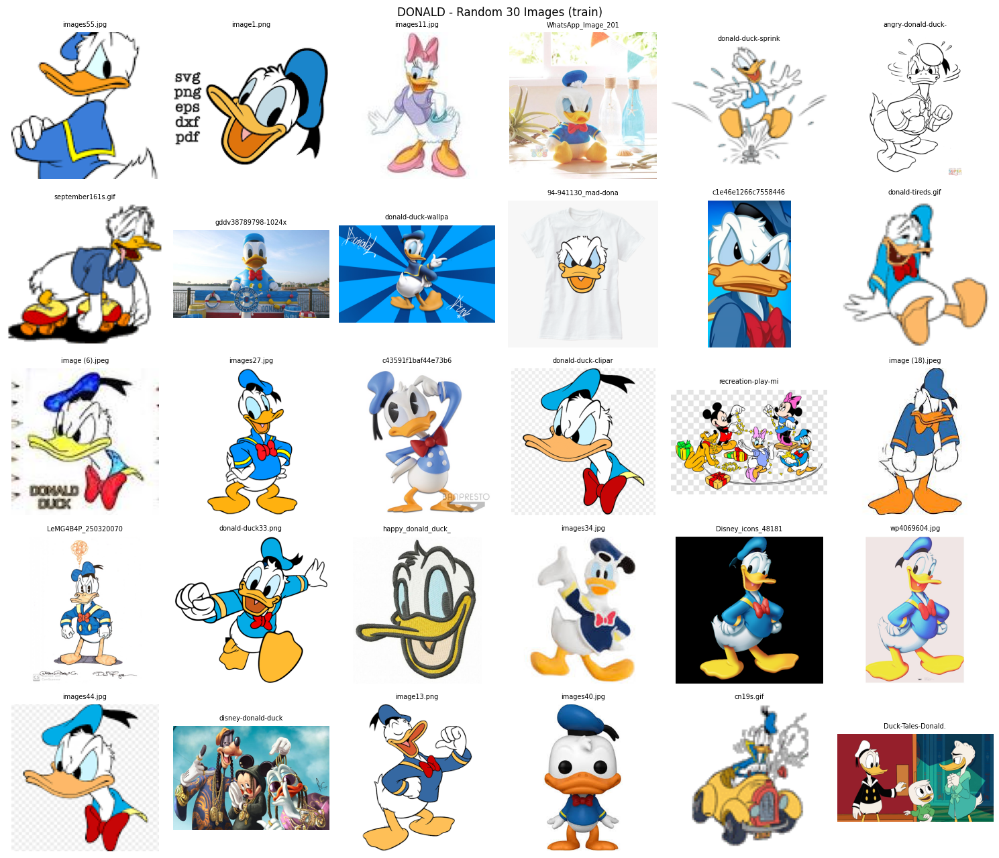

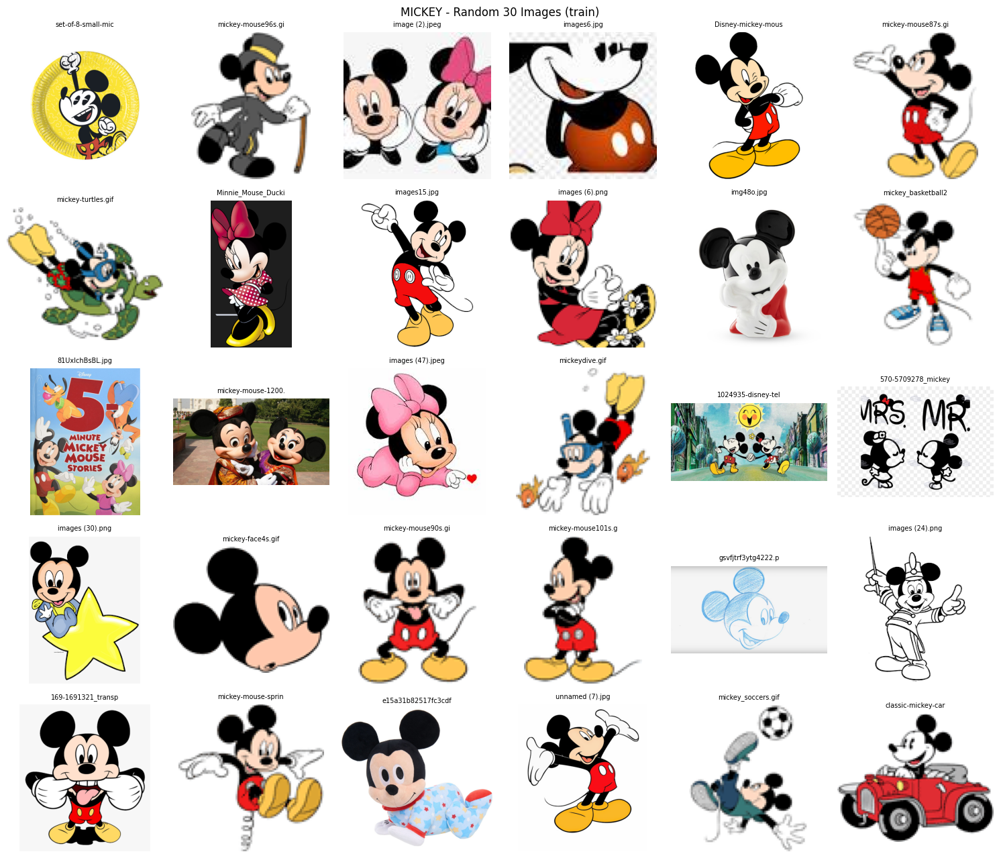

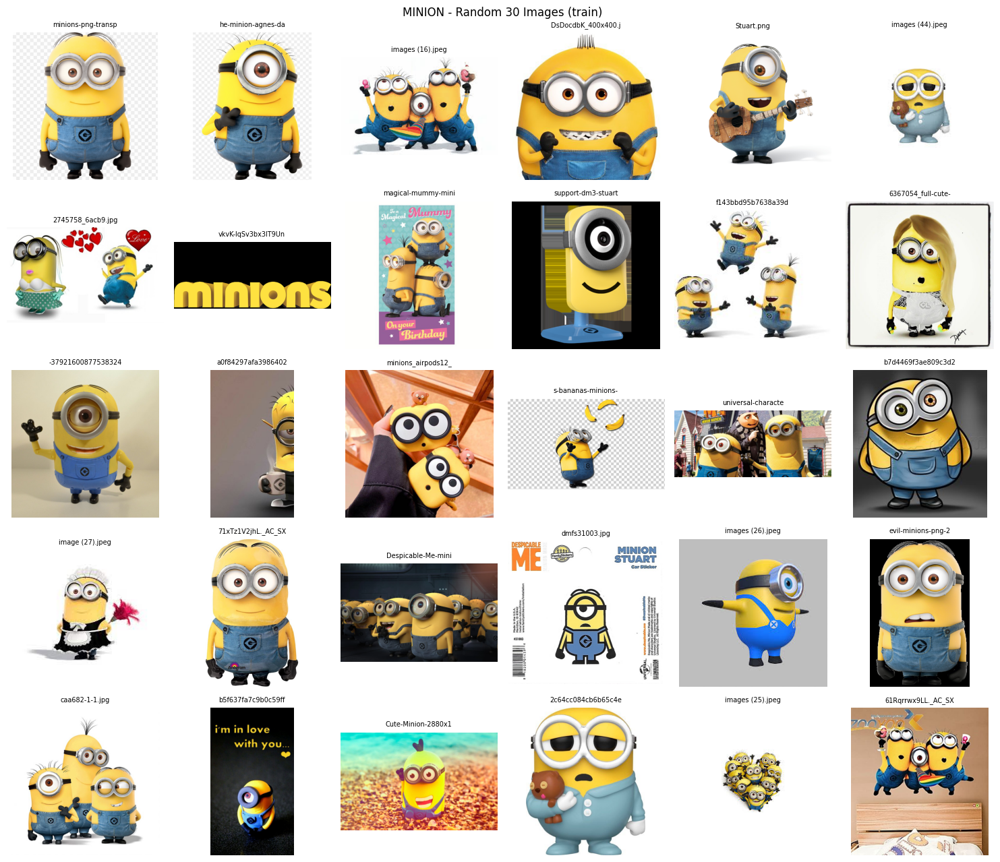

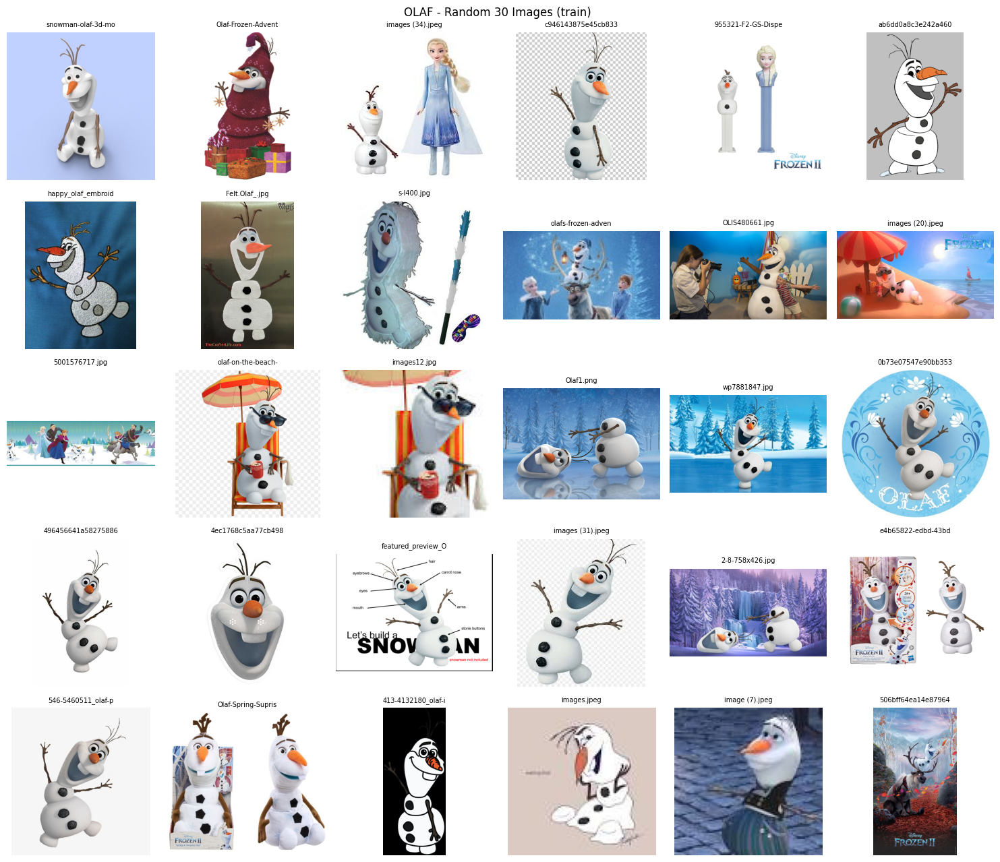

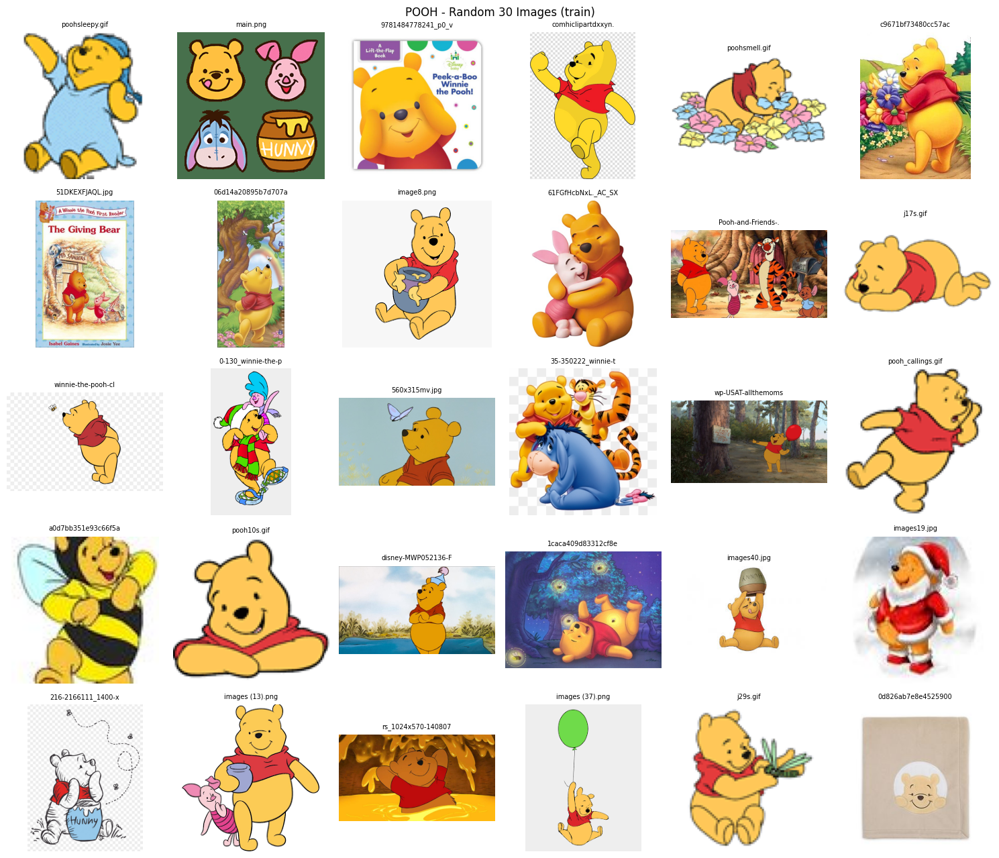

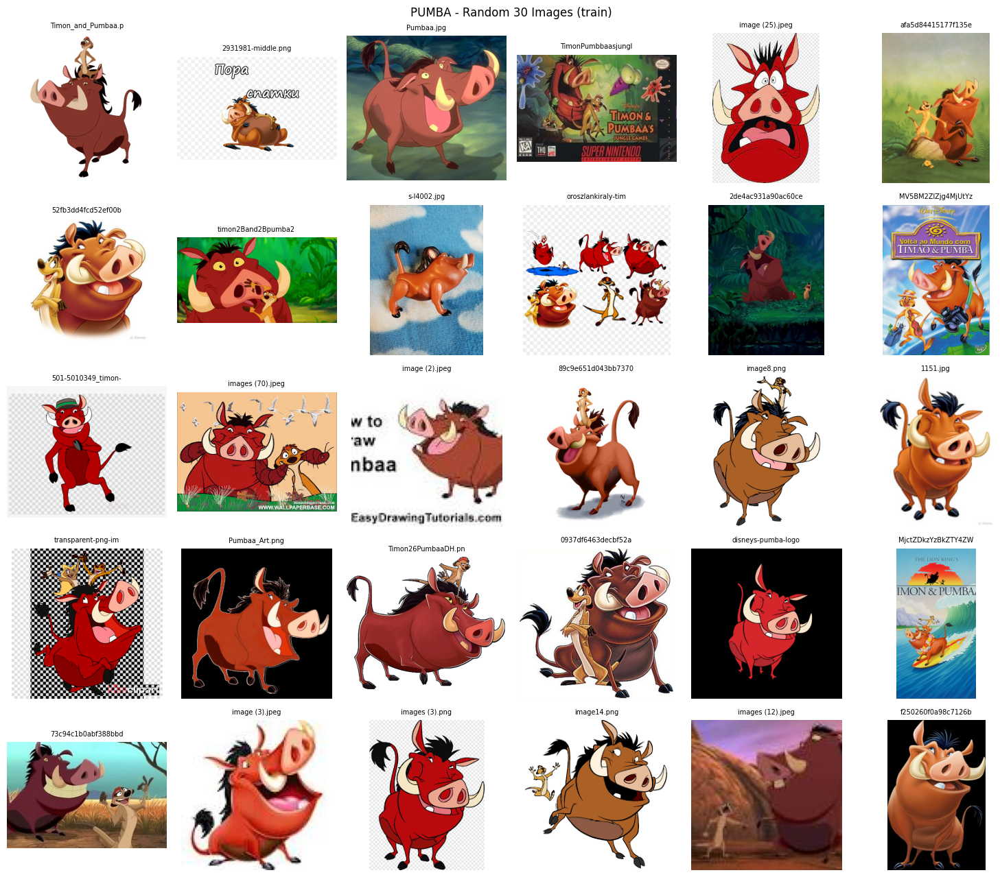

In [ ]:
def generate_class_samples(
    metadata,
    split="train",
    samples_per_class=30
):
    """
    display a eandom sample fo images for every class
    uses valid and recoverable images only here
    """

    valid_data = metadata[
        (metadata["split"] == split) &
        (metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        ))
    ]
    for class_name in CLASSES:
        class_data = valid_data[
            valid_data["class"] == class_name
        ]
        n_samples = min(
            samples_per_class,
            len(class_data)
        )
        sampled = class_data.sample(
            n=n_samples,
            random_state=SEED
        )
        fig, axes = plt.subplots(
            5, 6,
            figsize=(15, 13)
        )
        axes = axes.flatten()
        for ax in axes:
            ax.axis("off")
        for i, (_, row) in enumerate(sampled.iterrows()):
            with Image.open(row["path"]) as img:
                img.seek(0)
                ax = axes[i]
                ax.imshow(img.convert("RGB"))
                ax.set_title(
                    row["filename"][:18],
                    fontsize=7
                )
        plt.suptitle(
            f"{class_name.upper()} - Random {n_samples} Images ({split})"
        )
        plt.tight_layout()
        plt.show()

generate_class_samples(
    decode_df,
    split="train",
    samples_per_class=3
)

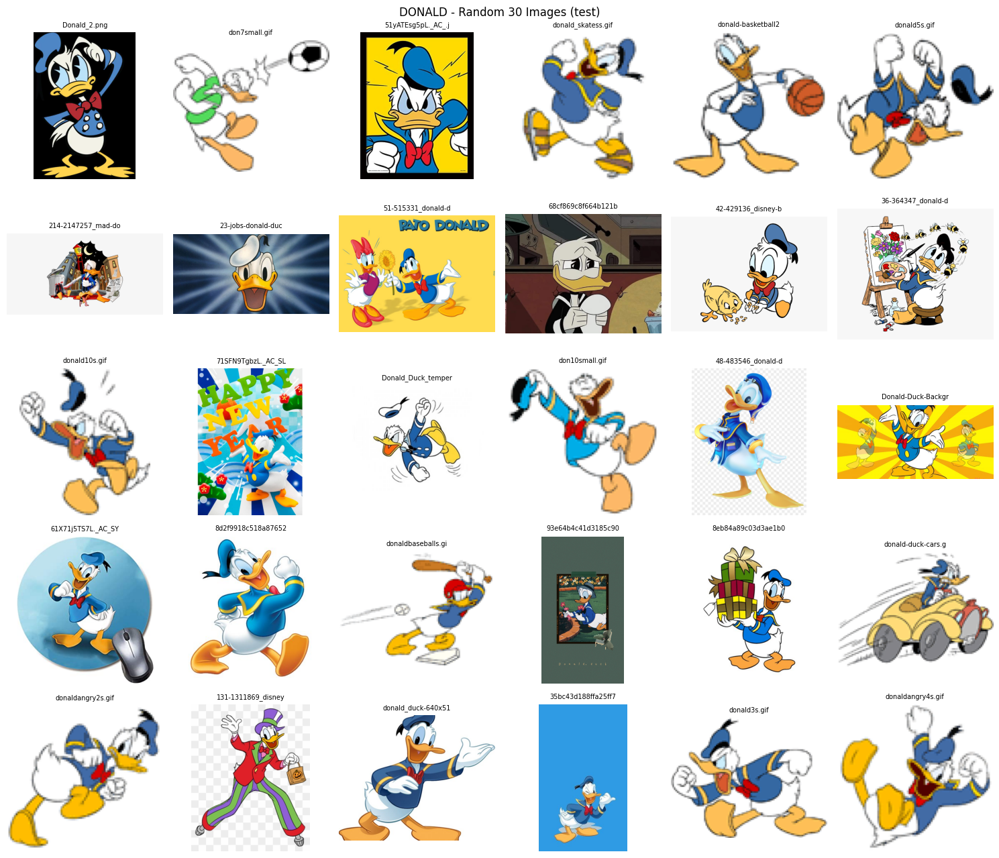

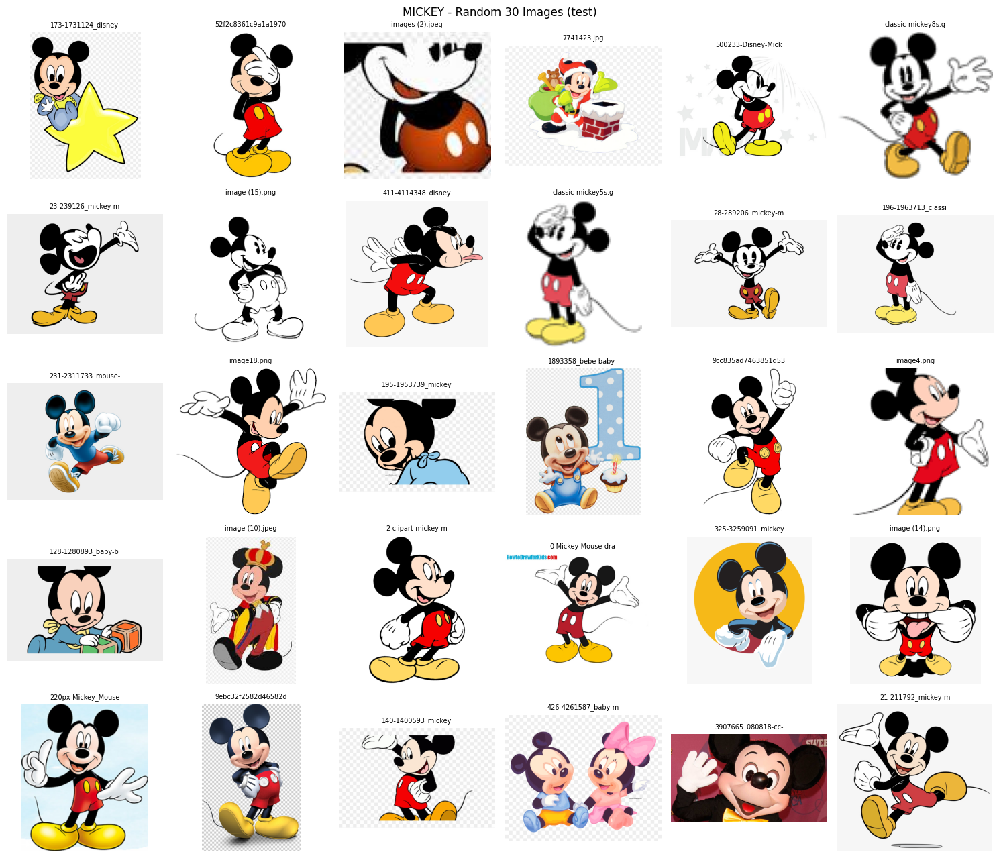

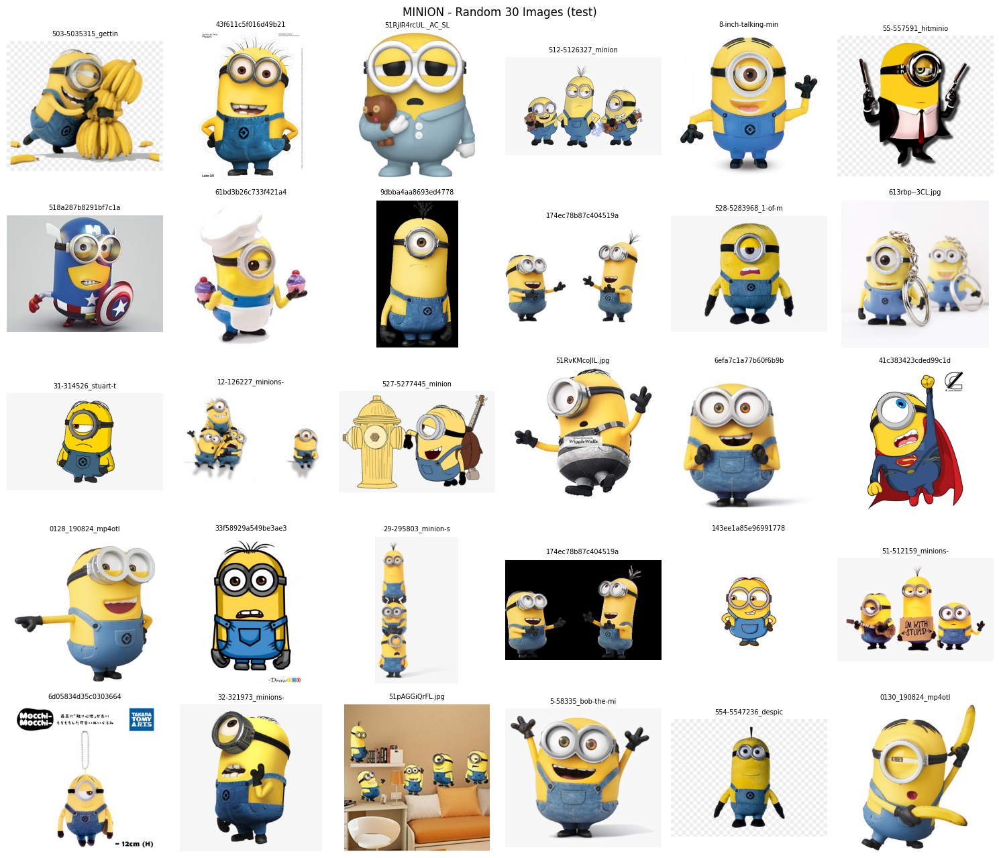

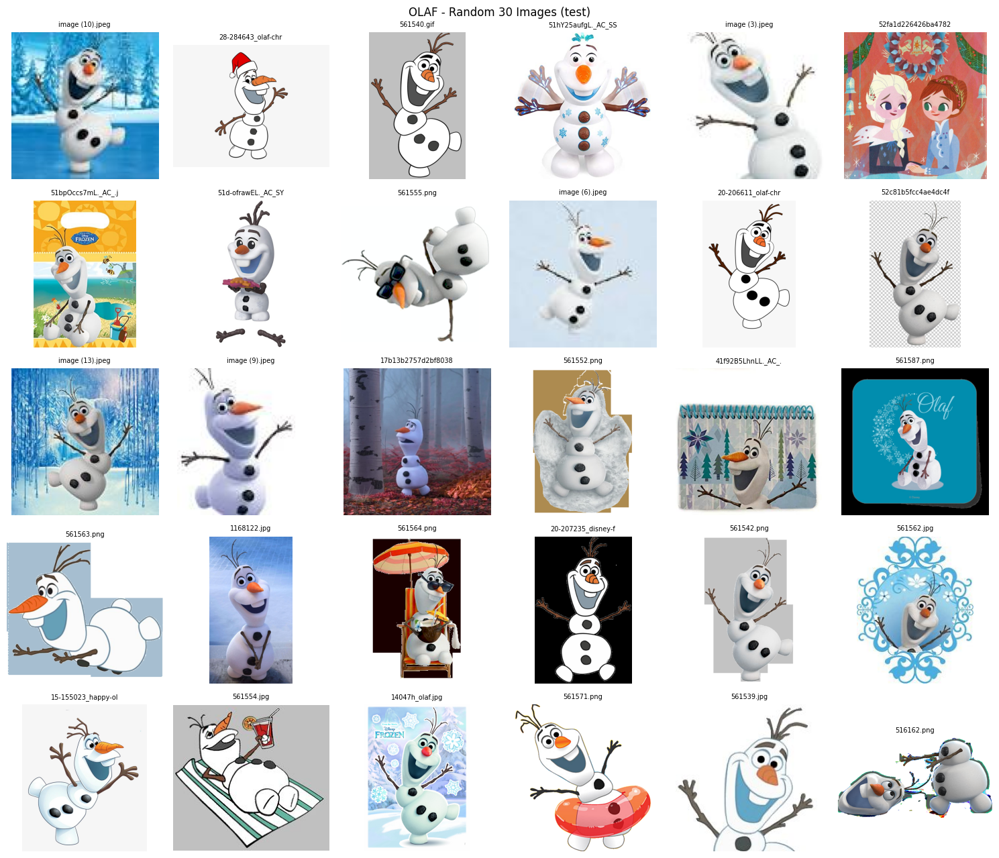

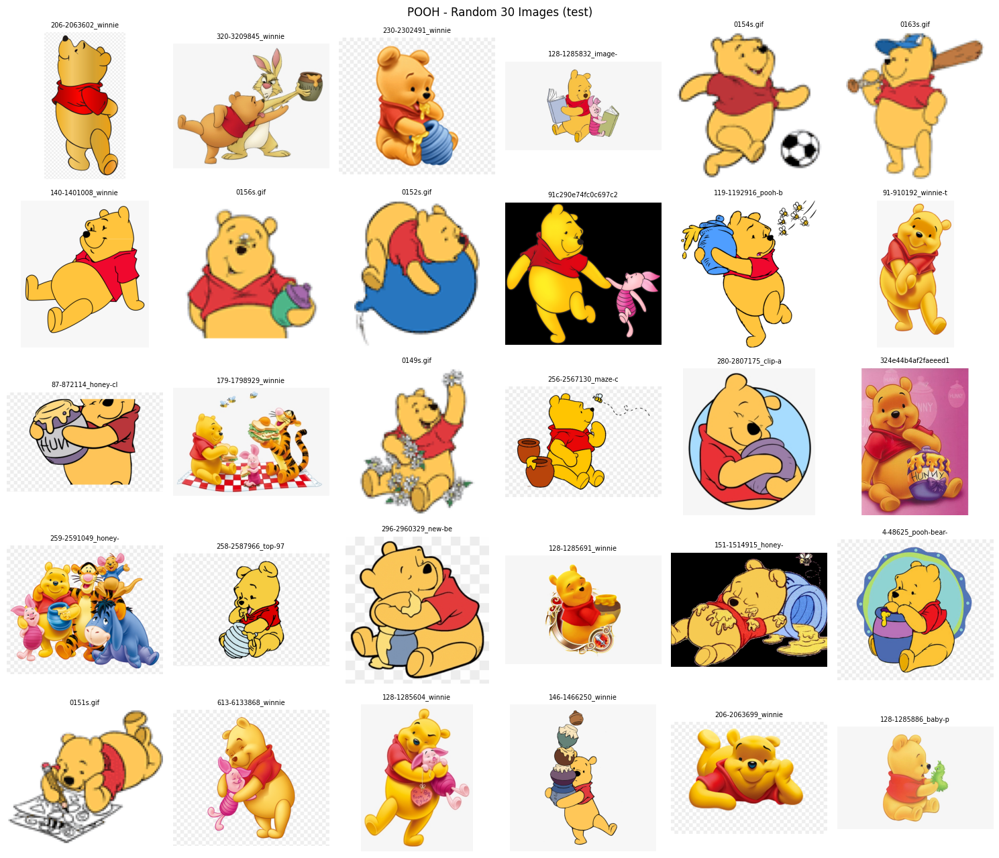

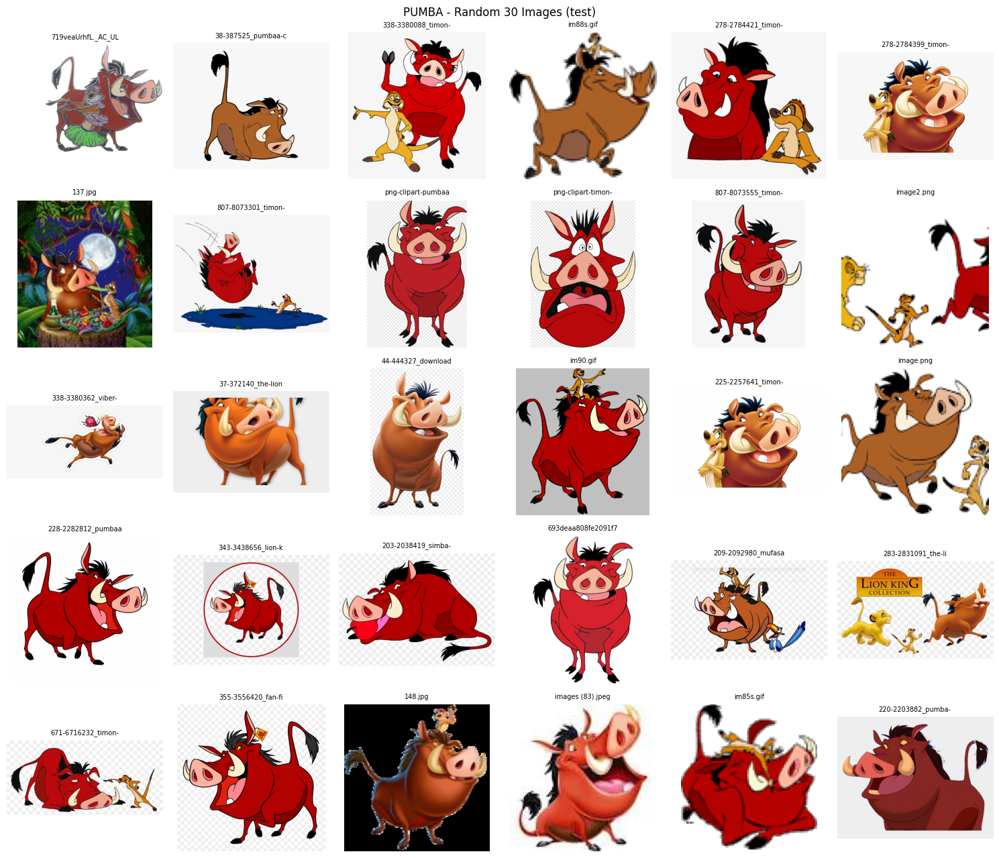

In [ ]:
generate_class_samples(
    decode_df,
    split="test",
    samples_per_class=30
)

In [ ]:
# create a manual review template from sampled images
def create_manual_review_template(
    metadata,
    split="train",
    samples_per_class=30
):
    """create a csv template for manual image inspection."""
    valid_data = metadata[
        (metadata["split"] == split) &
        (metadata["status"].isin(
            ["valid", "truncated_recoverable"]
        ))
    ]
    samples = []
    for class_name in CLASSES:
        class_data = valid_data[
            valid_data["class"] == class_name
        ]
        sampled = class_data.sample(
            n=min(samples_per_class, len(class_data)),
            random_state=SEED
        )
        for _, row in sampled.iterrows():
            samples.append({
                "path": row["path"],
                "split": split,
                "original_class": class_name,
                "decision": "keep",
                "correct_class": class_name,
                "multi_character": False,
                "watermark": False,
                "small_character": False,
                "comments": ""
            })
    review_df = pd.DataFrame(samples)
    output_path = (
        AUDIT_DIR / f"manual_review_{split}.csv"
    )
    review_df.to_csv(output_path, index=False)
    return review_df

train_review = create_manual_review_template(decode_df, "train", 30)
test_review = create_manual_review_template(decode_df, "test", 30)

print("Training review samples:", len(train_review))
print("Testing review samples:", len(test_review))
print("Review files saved in:", AUDIT_DIR)

Training review samples: 180
Testing review samples: 180
Review files saved in: /content/audit_results


In [ ]:
def generate_audit_summary(auditor, hash_data, near_duplicates):
    """generate a preliminary before-cleaning audit summary."""
    inventory = auditor.inventory
    readability = auditor.decode_results
    summary = {
        "Total files": len(inventory),
        "Valid images": int(
            readability["status"].isin(
                ["valid", "truncated_recoverable"]
            ).sum()
        ),
        "Strictly readable images": int(
            (readability["status"] == "valid").sum()
        ),
        "Recoverable truncated images": int(
            (readability["status"] == "truncated_recoverable").sum()
        ),
        "Corrupted files": int(
            (readability["status"] == "corrupted").sum()
        ),
        "Non-image files": int(
            (readability["status"] == "not_image").sum()
        ),
        "Files hashed": len(hash_data),
        "Near-duplicate candidate pairs": len(near_duplicates)
    }

    summary_df = pd.DataFrame(summary.items(),columns=["Metric", "Value"])
    display(summary_df)
    summary_df.to_csv(AUDIT_DIR / "preliminary_audit_summary.csv",index=False)
    return summary_df

preliminary_summary = generate_audit_summary(
    auditor,
    hash_df,
    near_duplicates
)
print("\nAudit reports saved at:", AUDIT_DIR)

,Metric,Value
0,Total files,4667
1,Valid images,4667
2,Strictly readable images,4666
3,Recoverable truncated images,1
4,Corrupted files,0
5,Non-image files,0
6,Files hashed,4666
7,Near-duplicate candidate pairs,310



Audit reports saved at: /content/audit_results


In [ ]:
# files that passed the readability check
valid_statuses = [
    "valid",
    "truncated_recoverable"
]

valid_files = decode_df[
    decode_df["status"].isin(valid_statuses)
].copy()

# Exact duplicate handling:
# Keep one copy of each SHA256 hash.
# Prefer the training copy if the duplicate occurs across splits.

hash_lookup = hash_df.set_index("path")["sha256"].to_dict()

valid_files["sha256"] = valid_files["path"].map(hash_lookup)

valid_files["split_priority"] = (
    valid_files["split"].map({"train": 0, "test": 1})
)

valid_files = valid_files.sort_values(
    ["split_priority", "path"]
)

exact_duplicate_paths = set(
    valid_files[
        valid_files.duplicated("sha256", keep="first")
    ]["path"]
)

print("Valid images:", len(valid_files))
print("Exact duplicate copies to remove:",
      len(exact_duplicate_paths))

# Remove exact duplicates
clean_candidates = valid_files[
    ~valid_files["path"].isin(exact_duplicate_paths)
].copy()

# Remove cross-split near-duplicate candidates from test.
# Training images are preferred.
near_duplicate_test_paths = set(
    near_duplicates["test_path"].unique()
) if len(near_duplicates) else set()

clean_candidates = clean_candidates[
    ~clean_candidates["path"].isin(
        near_duplicate_test_paths
    )
].copy()

print("Near-duplicate test images removed:",
      len(near_duplicate_test_paths))

print("Images remaining:", len(clean_candidates))


Valid images: 4667
Exact duplicate copies to remove: 149
Near-duplicate test images removed: 170
Images remaining: 4372


In [ ]:

def normalise_and_save_image(source_path, destination_path):
    """
    Convert an image to RGB and save it.

    Animated GIFs use their first frame.
    Transparent images are composited onto white.
    """

    with Image.open(source_path) as img:

        # Use first frame for GIFs and other animated images
        img.seek(0)

        # Convert to RGBA to handle transparency
        rgba = img.convert("RGBA")

        # Composite onto white background
        background = Image.new(
            "RGBA",
            rgba.size,
            (255, 255, 255, 255)
        )

        background.alpha_composite(rgba)

        # Convert to RGB
        rgb_image = background.convert("RGB")

        # Save as JPEG
        rgb_image.save(
            destination_path,
            format="JPEG",
            quality=95
        )


# Create cleaned dataset
for split in SPLITS:
    for class_name in CLASSES:
        (CLEANED_DIR / split / class_name).mkdir(
            parents=True,
            exist_ok=True
        )


cleaning_errors = []

for _, row in tqdm(
    clean_candidates.iterrows(),
    total=len(clean_candidates),
    desc="Creating cleaned dataset"
):

    source = Path(row["path"])

    destination = (
        CLEANED_DIR
        / row["split"]
        / row["class"]
        / f"{source.stem}.jpg"
    )

    # Avoid filename collisions
    if destination.exists():
        destination = destination.with_name(
            f"{source.stem}_{hashlib.md5(str(source).encode()).hexdigest()[:8]}.jpg"
        )

    try:
        normalise_and_save_image(
            source,
            destination
        )

    except Exception as e:
        cleaning_errors.append({
            "source": str(source),
            "error": str(e)
        })


print("Cleaning completed!")
print("Cleaning errors:", len(cleaning_errors))
print("Cleaned dataset:", CLEANED_DIR)

if cleaning_errors:
    display(pd.DataFrame(cleaning_errors).head(20))


Creating cleaned dataset:   0%|          | 0/4372 [00:00<?, ?it/s]

Cleaning completed!
Cleaning errors: 1
Cleaned dataset: /content/disney_cleaned


,source,error
0,/content/disney_dataset/cartoon/train/donald/h...,image file is truncated (5 bytes not processed)


In [ ]:
# Count final images
final_records = []

for split in SPLITS:
    for class_name in CLASSES:

        folder = CLEANED_DIR / split / class_name

        count = len(list(folder.glob("*.jpg")))

        final_records.append({
            "split": split,
            "class": class_name,
            "final_images": count
        })

final_counts_df = pd.DataFrame(final_records)

print("Final cleaned class distribution:")
display(
    final_counts_df.pivot(
        index="class",
        columns="split",
        values="final_images"
    )
)

# Overall summary
before_count = len(inventory_df)
valid_count = len(valid_files)
exact_removed = len(exact_duplicate_paths)
near_removed = len(near_duplicate_test_paths)

after_count = int(final_counts_df["final_images"].sum())

before_after_summary = pd.DataFrame({
    "Metric": [
        "Original files",
        "Valid/recoverable images",
        "Exact duplicate copies removed",
        "Near-duplicate test candidates removed",
        "Cleaning errors",
        "Final cleaned images"
    ],
    "Count": [
        before_count,
        valid_count,
        exact_removed,
        near_removed,
        len(cleaning_errors),
        after_count
    ]
})

display(before_after_summary)

before_after_summary.to_csv(
    AUDIT_DIR / "before_after_summary.csv",
    index=False
)

final_counts_df.to_csv(
    AUDIT_DIR / "final_class_distribution.csv",
    index=False
)


Final cleaned class distribution:


split,test,train
class,,
donald,86,633
mickey,69,715
minion,51,679
olaf,56,590
pooh,50,738
pumba,29,675


,Metric,Count
0,Original files,4667
1,Valid/recoverable images,4667
2,Exact duplicate copies removed,149
3,Near-duplicate test candidates removed,170
4,Cleaning errors,1
5,Final cleaned images,4371


In [ ]:
from sklearn.model_selection import train_test_split
from collections import Counter

def load_cartoon_data(
    cleaned_dir,
    classes,
    validation_size=0.15,
    random_state=42
):
    """
    Load cleaned cartoon dataset and create stratified splits.

    The provided test set is retained unchanged.
    Validation is sampled from the training set.
    """

    cleaned_dir = Path(cleaned_dir)

    paths = []
    labels = []

    # Collect cleaned training images
    for label, class_name in enumerate(classes):
        class_dir = cleaned_dir / "train" / class_name
        for image_path in sorted(class_dir.glob("*.jpg")):
            paths.append(str(image_path))
            labels.append(label)

    paths = np.array(paths)
    labels = np.array(labels)

    # Stratified train-validation split
    train_paths, val_paths, train_labels, val_labels = (
        train_test_split(
            paths,
            labels,
            test_size=validation_size,
            stratify=labels,
            random_state=random_state
        )
    )

    # Load provided test set without splitting
    test_paths = []
    test_labels = []

    for label, class_name in enumerate(classes):

        class_dir = cleaned_dir / "test" / class_name

        for image_path in sorted(class_dir.glob("*.jpg")):
            test_paths.append(str(image_path))
            test_labels.append(label)

    test_paths = np.array(test_paths)
    test_labels = np.array(test_labels)

    return {
        "train": (train_paths, train_labels),
        "validation": (val_paths, val_labels),
        "test": (
            np.array(test_paths),
            np.array(test_labels)
        )
    }


data_splits = load_cartoon_data(
    cleaned_dir=CLEANED_DIR,
    classes=CLASSES,
    validation_size=0.15,
    random_state=SEED
)

print("Dataset splitting completed!")

Dataset splitting completed!


In [ ]:
def print_split_statistics(data_splits, classes):
    """Print dataset sizes and class distributions."""

    rows = []

    for split_name, (paths, labels) in data_splits.items():

        counts = Counter(labels)

        print(f"\n{split_name.upper()} SET")
        print("Total images:", len(paths))

        for label, class_name in enumerate(classes):

            count = counts[label]

            print(f"{class_name}: {count}")

            rows.append({
                "split": split_name,
                "class": class_name,
                "count": count
            })

    return pd.DataFrame(rows)


split_statistics = print_split_statistics(
    data_splits,
    CLASSES
)

display(
    split_statistics.pivot(
        index="class",
        columns="split",
        values="count"
    )
)


TRAIN SET
Total images: 3425
donald: 538
mickey: 608
minion: 577
olaf: 501
pooh: 627
pumba: 574

VALIDATION SET
Total images: 605
donald: 95
mickey: 107
minion: 102
olaf: 89
pooh: 111
pumba: 101

TEST SET
Total images: 341
donald: 86
mickey: 69
minion: 51
olaf: 56
pooh: 50
pumba: 29


split,test,train,validation
class,,,
donald,86,538,95
mickey,69,608,107
minion,51,577,102
olaf,56,501,89
pooh,50,627,111
pumba,29,574,101


In [ ]:
def verify_split_independence(data_splits):
    """Verify that train, validation and test paths do not overlap."""

    train_paths = set(data_splits["train"][0])
    val_paths = set(data_splits["validation"][0])
    test_paths = set(data_splits["test"][0])

    train_val_overlap = train_paths.intersection(val_paths)
    train_test_overlap = train_paths.intersection(test_paths)
    val_test_overlap = val_paths.intersection(test_paths)

    print("Train-Validation overlap:", len(train_val_overlap))
    print("Train-Test overlap:", len(train_test_overlap))
    print("Validation-Test overlap:", len(val_test_overlap))

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0
    assert len(val_test_overlap) == 0

    print("\nPASS: No path overlap between the three splits.")

verify_split_independence(data_splits)

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

PASS: No path overlap between the three splits.


In [ ]:
from PIL import Image, ImageOps

def resize_with_padding(image, target_size=(64,64)):
  """
  resize the imges while preserving their aspect ratios"""

  image = image.convert("RGB")
  target_width,target_height = target_size

  #Resize while preserving aspect ratio
  resized = ImageOps.contain(
      image,
      target_size,
      method = Image.Resampling.LANCZOS
  )

  canvas = Image.new("RGB",target_size,(255,255,255))

  x_offset = (target_width - resized.width)//2
  y_offset = (target_height - resized.height)//2

  canvas.paste(resized,(x_offset,y_offset))

  return canvas

In [ ]:
from torch.utils.data import Dataset
from torchvision import transforms

class CartoonDataset(Dataset):
  """
  custom torch dataset for cartoon characters classification
  images are resized and cached in mem during initialisation
  """
  def __init__(
      self,
      image_paths,
      labels,
      image_size=(64,64),
      transform = None
  ):
    self.iamge_paths = list(image_paths)
    self.labels = torch.tensor(labels,dtype=torch.long)
    self.transform=transform
    self.images=[]

    for image_path in tqdm(
        self.image_paths,
        desc="Caching images"
    ):
      with Image.open(image_path) as img:
        img.seek(0)
        resized = resize_with_padding(img,target_size=image_size)
        self.images.append(resized.copy())

  def __len__(self):
    return len(self.labels)

  def __getitem__(self,index):
    """return trandformed image and corresponding label"""
    image = self.images[index].copy()
    label = self.labels[index]
    if self.transform is not None:
      image = self.transform(image)
    return image,label

In [ ]:
#get split info
train_paths,train_labels = data_splits["train"]
val_paths,val_labels = data_splits["validation"]
test_paths,test_labels = data_splits["test"]

train_dataset_base = CartoonDataset(
    train_paths,
    train_labels,
    image_size=TARGET_SIZE
)
val_dataset_base = CartoonDataset(
    val_paths,
    val_labels,
    image_size=TARGET_SIZE
)
test_dataset_base = CartoonDataset(
    test_paths,
    test_labels,
    image_size=TARGET_SIZE
)

print("\nCached dataset size:")
print("Train:", len(train_dataset_base))
print("Validation:", len(val_dataset_base))
print("Test:", len(test_dataset_base))

In [ ]:
to_tensor = transforms.ToTensor()
train_tensor_stack = torch.stack([
    to_tensor(image) for image in train_dataset_base.images
])
CHANNEL_MEAN = train_tensor_stack.mean(dim=(0,2,3))
CHANNEL_STD = train_tensor_stack.std(dim=(0,2,3),unbiased=False)

print("Training channel mean:", CHANNEL_MEAN)
print("Training channel std:", CHANNEL_STD)

print("\nRGB Mean:")
print(CHANNEL_MEAN.tolist())

print("\nRGB Standard Deviation:")
print(CHANNEL_STD.tolist())

del train_tensor_stack

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10,fill=(255,255,255)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=CHANNEL_MEAN.tolist(),
        std=CHANNEL_STD.tolist()
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=CHANNEL_MEAN.tolist(),
        std=CHANNEL_STD.tolist()
    )
])

print("Train and evaluation trandformstions defined")

In [ ]:
# training dataset with augumentation
train_dataset = CartoonDataset(
    train_paths,
    train_labels,
    image_size=TARGET_SIZE,
    transform=train_transform
)
#validation datadet without augumentation
val_dataset = CartoonDataset(
    val_paths,
    val_labels,
    image_size = TARGET_SIZE,
    transform = eval_transform
)
#test dataset without augumentation
test_dataset = CartoonDataset(
    test_paths,
    test_labels,
    image_size = TARGET_SIZE,
    transform= eval_transform
)

print("final dataset created sucessfully")

In [ ]:
from collections import Counter

train_class_counts = Counter(train_labels)
imbalance_df = pd.DataFrame([
    {
        "class": CLASSES[i],
        "count": train_class_counts[i]
    }
    for i in range(len(CLASSES))
])
display(imbalance_df)
imbalance_ratio=(
    imbalance_df["counts"].max() / imbalance_df["counts"].min()
)
print("Imbalance ratio:", round(imbalance_ratio,3))
USE_WEIGHTED_SAMPLER = imbalance_ratio >= 1.2
print("weighted sampler enabled:",USE_WEIGHTED_SAMPLER)

In [ ]:
from torch.utils.data import DataLoader,WeightedRandomSampler

BATCH_SIZE=64
NUM_WORKERS=2

if USE_WEIGHTED_SAMPLER:
  class_weight = {
      class_id: 1.0/train_class_counts[class_id]
      for class_id in range(len(CLASSES))
  }

  sample_weights = [
      class_weights[int(label)]
      for label in train_labels
  ]

  train_sampler = WeightedRandomSampler(
      weights=sample_weights,
      num_samples=len(sample_weights),
      replacement=True
  )

  train_loader = DataLoader(
      train_dataset,
      batch_size=BATCH_SIZE,
      sampler=train_sampler,
      num_workers=NUM_WORKERS,
      pin_memory=(DEVICE.type=="cuda")
  )

else:
  train_loader = DataLoader(
      train_dataset,
      batch_size=BATCH_SIZE,
      shuffle=True,
      num_workers=NUM_WORKERS,
      pin_memory=(DEVICE.type=="cuda")
  )


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type=="cuda")
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type=="cuda")
)

print("DataLoaders Created")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:",len(test_loader))

In [ ]:
def denormalize_image(image, mean, std):
    """reverse channel-wise image normalisation"""

    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return image * std + mean

def plot_augmented_samples(
    dataset,
    classes,
    num_samples=12
):
    """display augmented images from the training dataset"""

    indices = np.random.choice(
        len(dataset),
        size=min(num_samples, len(dataset)),
        replace=False
    )
    cols = 4
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 3 * rows)
    )
    axes = np.array(axes).flatten()
    for ax in axes:
        ax.axis("off")

    for i, index in enumerate(indices):
        image, label = dataset[index]
        image = denormalize_image(
            image,
            CHANNEL_MEAN.tolist(),
            CHANNEL_STD.tolist()
        )

        image = image.clamp(0, 1)
        axes[i].imshow(
            image.permute(1, 2, 0).numpy()
        )
        axes[i].set_title(
            classes[label.item()]
        )
        axes[i].axis("off")

    plt.suptitle("Randomly Augmented Training Samples")

    plt.text(
        0.95, 0.95, EMAIL_USERNAME,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig(
        AUDIT_DIR / "augmented_samples.png",
        dpi=300
    )
    plt.show()
plot_augmented_samples(
    train_dataset,
    CLASSES,
    num_samples=12
)

In [ ]:
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Image range:", images.min().item(),"to", images.max().item())
print("Unique labels:", torch.unique(labels))

assert images.shape[1:] == (3, 64, 64)
assert labels.ndim == 1
assert len(images) == len(labels)

print("\nPASS: Training batch verification successful.")

In [ ]:
import json

pipeline_config = {
    "seed": SEED,
    "classes": CLASSES,
    "image_size": list(TARGET_SIZE),
    "validation_size": 0.15,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "normalization_mean": CHANNEL_MEAN.tolist(),
    "normalization_std": CHANNEL_STD.tolist(),
    "weighted_sampler": USE_WEIGHTED_SAMPLER,
    "augmentation": [
        "RandomHorizontalFlip",
        "RandomRotation",
        "ColorJitter"
    ],
    "resize_policy": "Aspect-ratio preserving resize with white padding"
}

with open(
    AUDIT_DIR / "data_pipeline_config.json",
    "w"
) as f:
    json.dump(pipeline_config, f, indent=4)

print("Data pipeline configuration saved!")

In [ ]:
# CNN Architecture

import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import copy
import time
import json
import random

def set_seed(seed=36):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark=False

SEED=36
set_seed(SEED)

INPUT_CHANNELS=3
NUM_CLASSES=6
IMAGE_SIZE=64
FILTERS = [32,64,128]
DROPOUT_RATE=0.3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = path("/content/chackpoints")
CHECKPOINT_DIR.mkdir(parents=True,exist_ok=True)

print("Device:",DEVICE)
print("Number of classes:", NUM_CLASSES)
print("Filters:", FILTERS)

In [ ]:
class ConvBlock(nn.Module):
  """
  a convolutional block consisting of
  conv2D --> BatchNorm --> ReLU --> MaxPool2D
  """
  def __init__(self,in_channels,out_channels):
    super().__init__()
    self.conv=nn.Conv2d(
        in_channels=in_channels,
        out_channels=out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )
    self.bn = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace=True)
    self.pool = nn.MaxPool2d(kernel_size=2,stride=2)

  def forward(self,x):
    x=self.conv(x)
    x=self.bn(x)
    x=self.relu(x)
    x=self.pool(x)
    return x

In [ ]:
class CartoonCNN(nn.Module):
  """
  cnn architecture
  input
  --> convblock 1 (32 filters)
  --> convblock 2 (64 filters)
  --> convblock 3 (128 filters)
  --> global average pooling
  --> dropout
  --> fc
  """
  def __init__(
      self,
      num_classes=6,
      input_channels=3,
      filters=(32,64,128),
      dropout_rate=0.3
  ):
    super().__init__()
    self.block1=ConvBlock(input_channels,filters[0])
    self.block2=ConvBlock(filters[0],filters[1])
    self.block3=ConvBlock(filters[1],filters[2])
    self.global_pool=nn.AdaptiveAvgPool2d(output_size=1)
    self.dropout=nn.Dropout2d(p=dropout_rate)
    self.classifier=nn.Linear(filters[2],num_classes)
    self.initialize_weights()

  def initialize_weights(self):
    for module in self.modules():
      if isinstance(module,nn.Conv2d):
        nn.init.kaiming_normal_(
            module.weight,
            mode="fan_out",
            nonlinearity="relu"
        )
        if module.bias is not None:
          nn.init.zeros_(module.bias)
      elif isinstance(module,nn.Linear):
        nn.init.kaiming_normal_(
            module.weight,
            mode="fan_in",
            nonlinearity="relu"
        )
        nn.init.zeros_(module.bias)

  def forward(self, x, return_features=False):
    """
    forward pass through the complete cnn model
    """
    features={}
    x = self.block1(x)
    features["block1"]=x
    x = self.block2(x)
    features["block2"]=x
    x = self.block3(x)
    features["block3"]=x

    x = self.global_pool(x)
    x = torch.flatten(x, start_dim=1)
    x = self.dropout(x)
    logits = self.classifier(x)

    if return_features:
      return logits, features

    return logits

In [ ]:
model = CartoonCNN(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS,
    filters=FILTERS,
    dropout_rate=DROPOUT_RATE
).to(DEVICE)

dummy_input = torch.randn(4, 3, 64, 64).to(DEVICE)
model.eval()
with torch.no_grad():
    logits, feature_maps = model(
        dummy_input,
        return_features=True
    )

print("Input shape:", dummy_input.shape)
print("Output logits shape:", logits.shape)

print("\nIntermediate feature map shapes:")

for name, feature in feature_maps.items():
    print(name, ":", feature.shape)

assert logits.shape == (4, 6)
assert feature_maps["block1"].shape == (4, 32, 32, 32)
assert feature_maps["block2"].shape == (4, 64, 16, 16)
assert feature_maps["block3"].shape == (4, 128, 8, 8)

print("\nPASS: Architecture verification successful.")

In [ ]:
def count_parameters(module):
    """count trainable parameters in a module"""

    return sum(
        p.numel()
        for p in module.parameters()
        if p.requires_grad
    )

def generate_architecture_summary(model):
    """generate a table of architecture shapes and parameter counts"""
    layer_data = [
        {
            "Layer": "Input",
            "Output Shape": "(3, 64, 64)",
            "Parameters": 0
        },
        {
            "Layer": "Conv Block 1",
            "Output Shape": "(32, 32, 32)",
            "Parameters": count_parameters(model.block1)
        },
        {
            "Layer": "Conv Block 2",
            "Output Shape": "(64, 16, 16)",
            "Parameters": count_parameters(model.block2)
        },
        {
            "Layer": "Conv Block 3",
            "Output Shape": "(128, 8, 8)",
            "Parameters": count_parameters(model.block3)
        },
        {
            "Layer": "Global Average Pooling",
            "Output Shape": "(128, 1, 1)",
            "Parameters": count_parameters(model.global_pool)
        },
        {
            "Layer": "Dropout",
            "Output Shape": "(128)",
            "Parameters": count_parameters(model.dropout)
        },
        {
            "Layer": "Fully Connected",
            "Output Shape": "(6)",
            "Parameters": count_parameters(model.classifier)
        }
    ]
    summary_df = pd.DataFrame(layer_data)
    total_params = count_parameters(model)
    total_row = pd.DataFrame([{
        "Layer": "TOTAL",
        "Output Shape": "-",
        "Parameters": total_params
    }])
    summary_df = pd.concat(
        [summary_df, total_row],
        ignore_index=True
    )
    return summary_df

architecture_summary = generate_architecture_summary(model)
display(architecture_summary)
total_parameters = count_parameters(model)
print(f"\nTotal trainable parameters: {total_parameters:,}")

In [ ]:
def calculate_model_size(model):
  """estimate model parameter storage size"""
  parameter_size = sum(
      p.numel() * p.element_size()
      for p in model.parameters()
  )
  buffer_size = sum(
      b.numel() * b.element_size()
      for b in model.buffers()
  )
  total_size_mb = (parameter_size + buffer_size)/(1024**2)
  return total_size_mb

print(f"Model size: {calculate_model_size(model):.2f} MB")

In [ ]:
class Trainer:
    """
    trainer class for our CartoonCNN
    """
    def __init__(
        self,
        model,
        train_loader,
        val_loader,
        optimizer_name="Adam",
        learning_rate=0.001,
        weight_decay=0.0001,
        momentum=0.9,
        patience=7,
        max_epochs=30,
        checkpoint_path="/content/checkpoints/best_model.pth",
        device=DEVICE
    ):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.model.to(self.device)
        self.criterion = nn.CrossEntropyLoss()
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay

        if optimizer_name.lower() == "adam":
            self.optimizer = torch.optim.Adam(
                self.model.parameters(),
                lr=learning_rate,
                weight_decay=weight_decay
            )
        elif optimizer_name.lower() == "adamw":
            self.optimizer = torch.optim.AdamW(
                self.model.parameters(),
                lr=learning_rate,
                weight_decay=weight_decay
            )
        elif optimizer_name.lower() == "sgd":
            self.optimizer = torch.optim.SGD(
                self.model.parameters(),
                lr=learning_rate,
                momentum=momentum,
                weight_decay=weight_decay
            )
        else:
            raise ValueError(
                "Optimizer must be SGD, Adam or AdamW."
            )

        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode="max",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        )

        self.patience = patience
        self.max_epochs = max_epochs
        self.checkpoint_path = Path(checkpoint_path)
        self.checkpoint_path.parent.mkdir(parents=True,exist_ok=True)
        self.history = {
            "train_loss": [],
            "val_loss": [],
            "train_accuracy": [],
            "val_accuracy": [],
            "learning_rate": []
        }
        self.best_val_accuracy = 0.0
        self.best_epoch = 0

    def run_epoch(self, loader, training=True):
        if training:
            self.model.train()
        else:
            self.model.eval()

        total_loss = 0.0
        correct = 0
        total = 0
        context = torch.enable_grad() if training else torch.no_grad()
        with context:
            for images, labels in loader:
                images = images.to(self.device,non_blocking=True)
                labels = labels.to(self.device,non_blocking=True)
                if training:
                    self.optimizer.zero_grad(set_to_none=True)

                logits = self.model(images)
                loss = self.criterion(logits,labels)
                if training:
                    loss.backward()
                    self.optimizer.step()

                batch_size = labels.size(0)
                total_loss += loss.item() * batch_size
                predictions = torch.argmax(logits,dim=1)
                correct += (predictions == labels).sum().item()
                total += batch_size

        average_loss = total_loss / total
        accuracy = correct / total
        return average_loss, accuracy

    def save_checkpoint(self, epoch, val_accuracy):
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": self.model.state_dict(),
            "optimizer_state_dict": self.optimizer.state_dict(),
            "val_accuracy": val_accuracy
        }
        torch.save(checkpoint,self.checkpoint_path)

    def fit(self):
        epochs_without_improvement = 0
        for epoch in range(1, self.max_epochs + 1):
            start_time = time.time()
            train_loss, train_accuracy = self.run_epoch(
                self.train_loader,
                training=True
            )
            val_loss, val_accuracy = self.run_epoch(
                self.val_loader,
                training=False
            )
            self.scheduler.step(val_accuracy)
            current_lr = self.optimizer.param_groups[0]["lr"]
            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["train_accuracy"].append(train_accuracy)
            self.history["val_accuracy"].append(val_accuracy)
            self.history["learning_rate"].append(current_lr)
            if val_accuracy > self.best_val_accuracy:
                self.best_val_accuracy = val_accuracy
                self.best_epoch = epoch
                self.save_checkpoint(
                    epoch,
                    val_accuracy
                )
                epochs_without_improvement = 0
                status = "Best model saved"
            else:
                epochs_without_improvement += 1
                status = (
                    f"No improvement "
                    f"({epochs_without_improvement}/{self.patience})"
                )
            epoch_time = time.time() - start_time
            print(
                f"Epoch [{epoch:02d}/{self.max_epochs}] "
                f"| Train Loss: {train_loss:.4f} "
                f"| Train Acc: {train_accuracy:.4f} "
                f"| Val Loss: {val_loss:.4f} "
                f"| Val Acc: {val_accuracy:.4f} "
                f"| LR: {current_lr:.6f} "
                f"| Time: {epoch_time:.2f}s "
                f"| {status}"
            )

            if epochs_without_improvement >= self.patience:
                print(f"\nEarly stopping at epoch {epoch}.")
                break

        print("\nTraining completed!")
        print("Best epoch:", self.best_epoch)
        print(
            "Best validation accuracy:",
            round(self.best_val_accuracy, 4)
        )
        print("Best checkpoint:",self.checkpoint_path)
        return pd.DataFrame(self.history)

In [ ]:
set_seed(SEED)
model=CartoonCNN(
    num_classes=NUM_CLASSES,
    input_channels=INPUT_CHANNELS,
    filters=FILTERS,
    dropout_rate=DROPOUT_RATE
).to(DEVICE)

trainer=Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_name="Adam",
    learning_rate=0.001,
    weight_decay=0.0001,
    patience=7,
    max_epochs=30,
    checkpoint_path="/content/checkpoints/best_model.pth",
    device=DEVICE
)

history_df=trainer.fit()
history_df.to_csv("/content/checkpoints/training_history.csv",index=False)

In [ ]:
def plot_training_loss(history, username):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )
    plt.plot(
        epochs,
        history["val_loss"],
        marker="o",
        label="Validation Loss"
    )
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.text(
        0.95, 0.95, username,
        ha="right", va="top",
        transform=plt.gca().transAxes,
        fontsize=10, color="gray", alpha=0.7
    )
    plt.tight_layout()
    plt.savefig("/content/checkpoints/loss_curve.png",dpi=300)
    plt.show()

plot_training_loss(trainer.history,EMAIL_USERNAME)

In [ ]:
def plot_training_accuracy(history,username):
  epochs=range(1,len(history["train_accuracy"])+1)
  plt.figure(figsize=(9,5))
  plt.plot(
      epochs,
      history["train_accuracy"],
      marker="o",
      label="Training Accuracy"
  )
  plt.plot(
      epochs,
      history["val_accuracy"],
      marker="o",
      label="validation Accuracy"
  )
  plt.title("Training and validation Accuracy")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.text(
      0.95, 0.95, username,
      ha="right", va="top",
      transform=plt.gca().transAxes,
      fontsize=10, color="gray", alpha=0.7
  )
  plt.tight_layout()
  plt.savefig("/content/checkpoints/accuracy_curve.png",dpi=300)
  plt.show()

plot_training_accuracy(trainer.history,EMAIL_USERNAME)

In [ ]:
checkpoint_path = "/content/checkpoints/best_model.pth"
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
    )
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()
print("best checkpoint loaded successfully")
print("Best epoch:",checkpoint["epoch"])
print("Best validation accuray:",checkpoint["val_accuracy"])

In [ ]:
part_c_results = {
    "seed": SEED,
    "architecture": "CartoonCNN",
    "input_shape": [3, 64, 64],
    "filters": FILTERS,
    "num_blocks": len(FILTERS),
    "num_classes": NUM_CLASSES,
    "dropout_rate": DROPOUT_RATE,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "best_epoch": trainer.best_epoch,
    "best_validation_accuracy": trainer.best_val_accuracy,
    "total_parameters": count_parameters(model),
    "model_size_mb": calculate_model_size(model)
}

with open("/content/checkpoints/part_c_results.json","w") as f:
    json.dump(part_c_results, f, indent=4)

display(
    pd.DataFrame(
        part_c_results.items(),
        columns=["Parameter", "Value"]
    )
)

print("Part C results saved!")